# Практическое занятие №5: Основные характеристики цифровых фильтров

## Импорт библиотек

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.signal import savgol_filter, savgol_coeffs

%matplotlib inline
np.random.seed(5)
plt.rcParams.update({'figure.figsize': (12, 4), 'axes.grid': True})

def amplitude_spectrum(x, fs):
    amp = abs(np.fft.rfft(x))/len(x)
    amp[1:(len(x)+1)//2] *= 2
    return np.fft.rfftfreq(len(x), 1/fs), amp

def response(b, a, fs):
    f = (np.arange(1024) + 0.5)*fs/2048
    _, H = signal.freqz(b, a, worN=f, fs=fs)
    _, gd = signal.group_delay((b, a), w=f, fs=fs)
    gd[abs(H) < 1e-5] = np.nan
    return f, H, gd

def plot_filter_response(b, a, fs, title):
    f, H, gd = response(b, a, fs)
    fig, axes = plt.subplots(4, 1, figsize=(10, 9), sharex=True)
    values = [abs(H), 20*np.log10(abs(H)+1e-12), np.unwrap(np.angle(H)), gd]
    labels = ['Амплитуда', 'Усиление, дБ', 'Фаза, рад', 'Задержка, отсч.']
    for ax, y, label in zip(axes, values, labels):
        ax.plot(f, y)
        ax.set_ylabel(label)
    axes[0].set_title(title)
    axes[-1].set_xlabel('Частота, Гц')
    plt.tight_layout()
    plt.show()

## Часть 1. КИХ-фильтр: скользящее среднее

**Скользящее среднее** – простейший КИХ-фильтр. Его коэффициенты: `b_k = 1/M` для `k = 0,...,M-1`. Фильтр имеет линейную фазу.

### Задание 1.1. Импульсная и переходная характеристики

Для длины окна `M = 5`:
1. Сформируйте массив коэффициентов `b` (нормированный).
2. Создайте тестовые сигналы: единичный импульс (длиной 20 отсчётов) и единичный скачок (длиной 50 отсчётов).
3. Примените фильтр с помощью `signal.lfilter(b, a, x)`, где `a = [1]`.
4. Постройте импульсную и переходную характеристики.


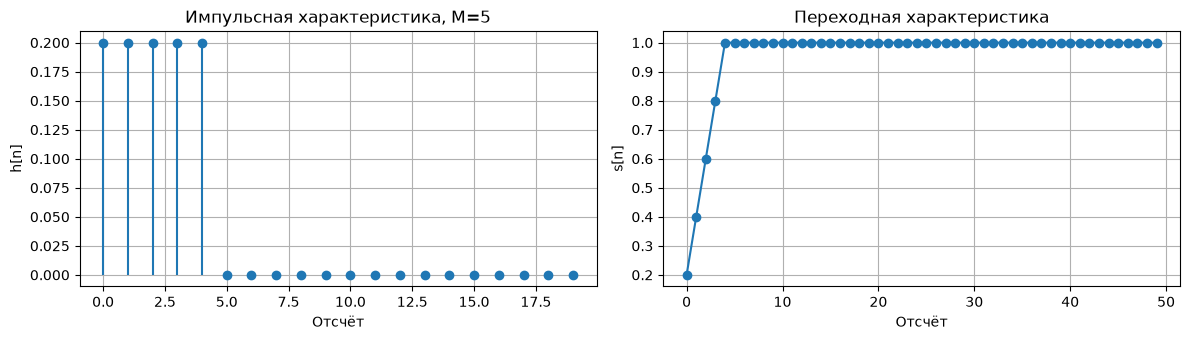

Первые коэффициенты h: [0.2 0.2 0.2 0.2 0.2 0.  0. ]
Установившийся уровень: 1.0


In [2]:
M = 5
b = np.ones(M)/M
a = [1]
impulse = np.zeros(20)
impulse[0] = 1
h = signal.lfilter(b, a, impulse)
s = signal.lfilter(b, a, np.ones(50))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].stem(np.arange(len(h)), h, basefmt=' ')
axes[0].set(title='Импульсная характеристика, M=5', xlabel='Отсчёт', ylabel='h[n]')
axes[1].plot(s, 'o-')
axes[1].set(title='Переходная характеристика', xlabel='Отсчёт', ylabel='s[n]')
plt.tight_layout()
plt.show()
print('Первые коэффициенты h:', h[:7])
print('Установившийся уровень:', s[-1])

**Вопрос:** Почему импульсная характеристика имеет конечную длину, а переходная выходит на постоянный уровень?


импульс дал пять отсчётов по 0,2, а ступень поднялась до 1 за пять отсчётов. фильтр берёт среднее пяти последних значений резкое изменение на выходе становится плавнее.

### Задание 1.2. АЧХ и ФЧХ

Используя функцию `plot_filter_response`, постройте характеристики для скользящего среднего с длинами окон `M = 5`, `M = 10`, `M = 20`.


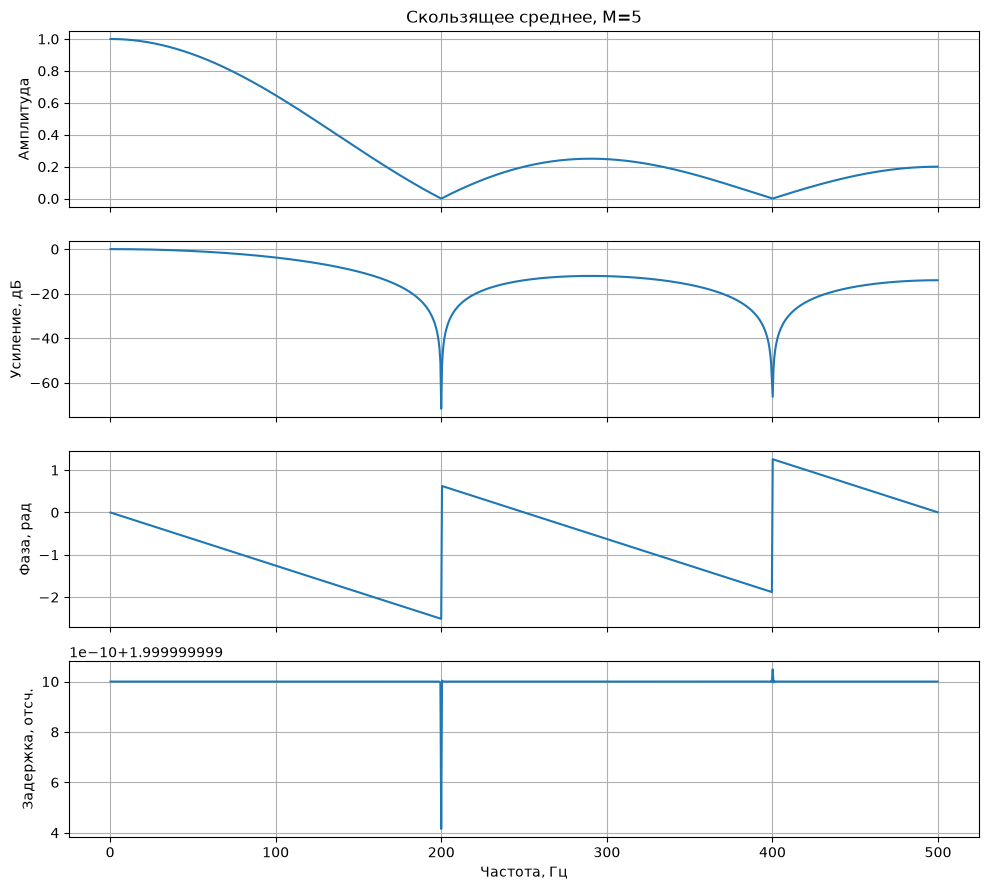

M=5: первый ноль 200.0 Гц, задержка 2.0 отсчёта


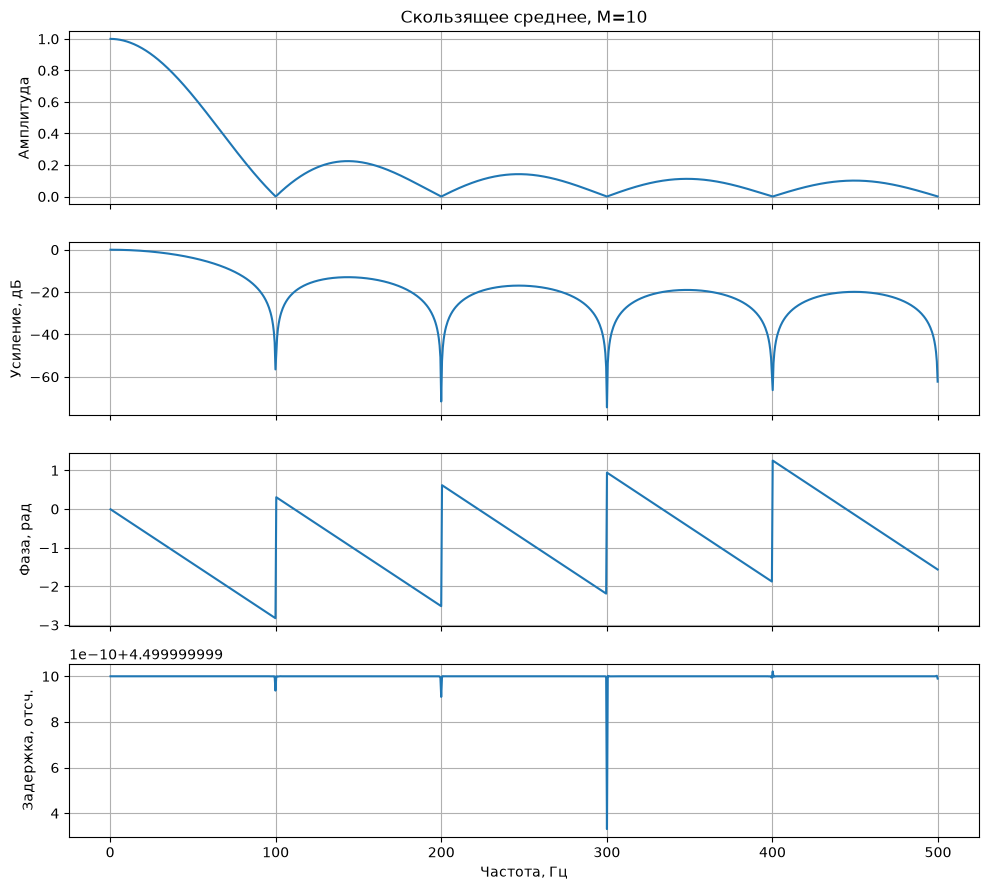

M=10: первый ноль 100.0 Гц, задержка 4.5 отсчёта


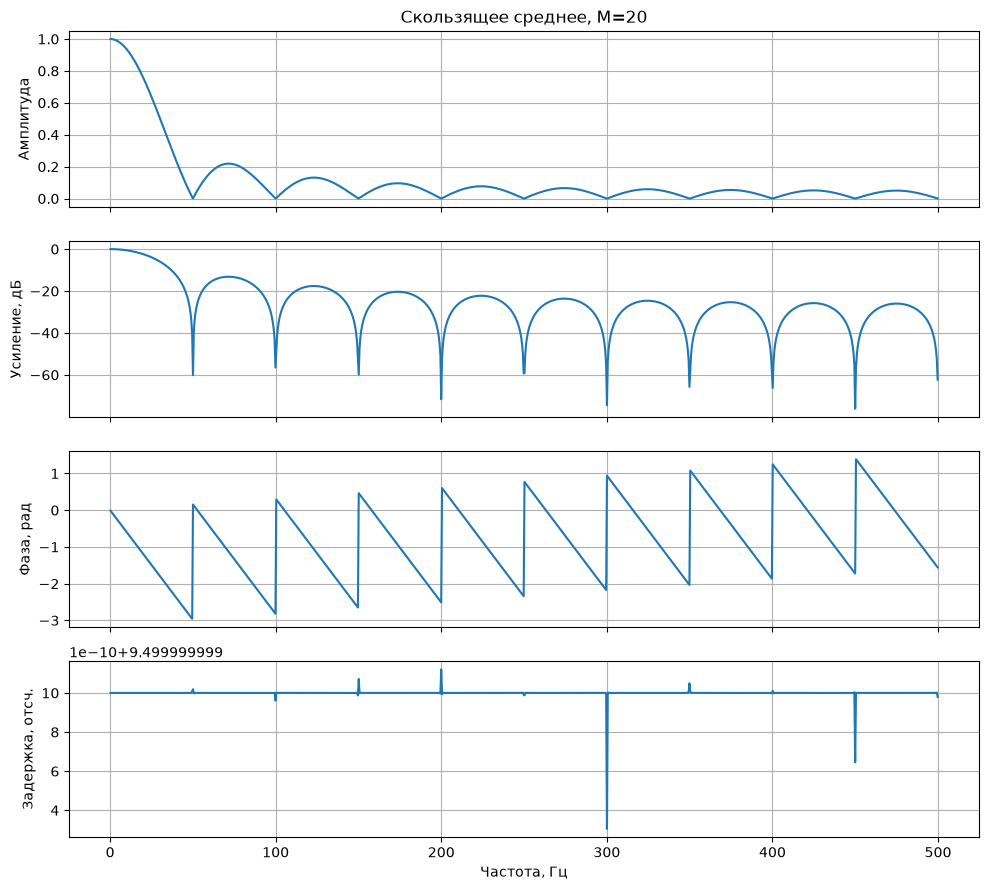

M=20: первый ноль 50.0 Гц, задержка 9.5 отсчёта


In [3]:
for M in [5, 10, 20]:
    plot_filter_response(np.ones(M)/M, [1], fs=1000, title=f'Скользящее среднее, M={M}')
    print(f'M={M}: первый ноль {1000/M:.1f} Гц, задержка {(M-1)/2:.1f} отсчёта')

**Вопрос:** Как изменение `M` влияет на крутизну среза АЧХ и на ФЧХ?


С ростом M полоса сужается, а задержка растёт. Первые нули получились на 200, 100 и 50 Гц, задержки — 2, 4,5 и 9,5 отсчёта. Фаза между нулями линейная.

### Задание 1.3. Фильтрация суммы синусоид

Сгенерируйте сигнал длительностью 1 с (fs=1000 Гц): `x = sin(2π·10·t) + 0.5·sin(2π·100·t)`. Примените скользящее среднее с `M=5` и `M=20`. Постройте временные графики и спектры (амплитудный спектр через БПФ).


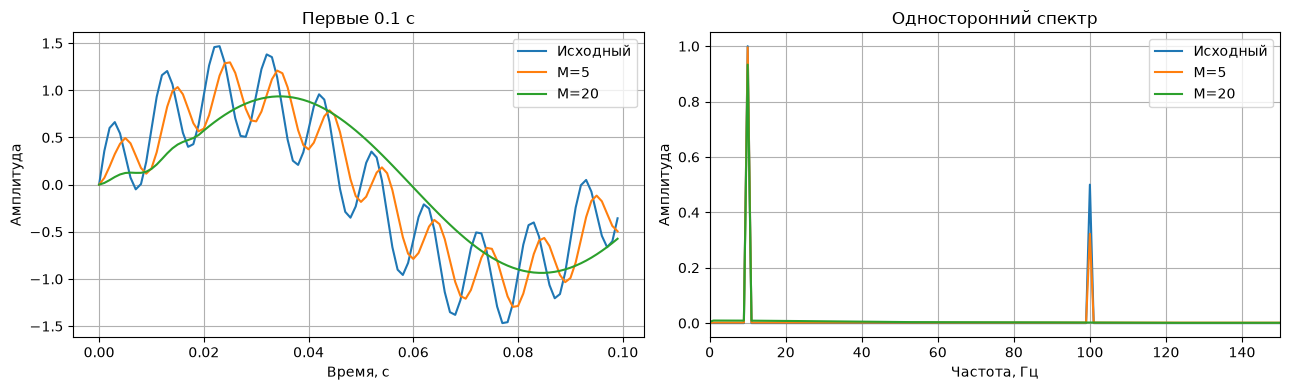

M=5: установившиеся амплитуды 10 Гц = 0.9961, 100 Гц = 0.3236
M=20: установившиеся амплитуды 10 Гц = 0.9356, 100 Гц = 0.0000


In [4]:
fs = 1000
t = np.arange(fs)/fs
x = np.sin(2*np.pi*10*t) + 0.5*np.sin(2*np.pi*100*t)
y5 = signal.lfilter(np.ones(5)/5, [1], x)
y20 = signal.lfilter(np.ones(20)/20, [1], x)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, y in [('Исходный', x), ('M=5', y5), ('M=20', y20)]:
    axes[0].plot(t[:100], y[:100], label=label)
    f, amp = amplitude_spectrum(y, fs)
    axes[1].plot(f, amp, label=label)
axes[0].set(xlabel='Время, с', ylabel='Амплитуда', title='Первые 0.1 с')
axes[1].set(xlabel='Частота, Гц', ylabel='Амплитуда', xlim=(0, 150), title='Односторонний спектр')
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()
for M in [5, 20]:
    _, H = signal.freqz(np.ones(M)/M, [1], worN=[10, 100], fs=fs)
    print(f'M={M}: установившиеся амплитуды 10 Гц = {abs(H[0]):.4f}, 100 Гц = {0.5*abs(H[1]):.4f}')

**Вопрос:** Как значение `M` влияет на амплитуду 100 Гц сигнала? Объясните, почему так. Какая связь между АЧХ и результатом фильтрации?


Для M=5 составляющая 100 Гц: амплитуда около 0,324 вместо 0,5. При M=20 она попала в ноль АЧХ и почти пропала. амплитуда на выходе равна входной амплитуде, умноженной на модуль АЧХ на этой частоте.

## Часть 2. БИХ-фильтр: экспоненциальное сглаживание

Фильтр первого порядка: `y[n] = α x[n] + (1-α) y[n-1]`. Коэффициенты: `b = [α]`, `a = [1, -(1-α)]`.

### Задание 2.1. Реализация и характеристики

Для `α = 0.2`:
1. Постройте импульсную характеристику (50 отсчётов) и переходную характеристику.
2. Используя `plot_filter_response`, постройте АЧХ, ФЧХ и групповую задержку.
3. Запишите передаточную функцию $H(z)$ фильтра и найдите её полюс (вручную и с помощью `signal.tf2zpk(b, a)`).

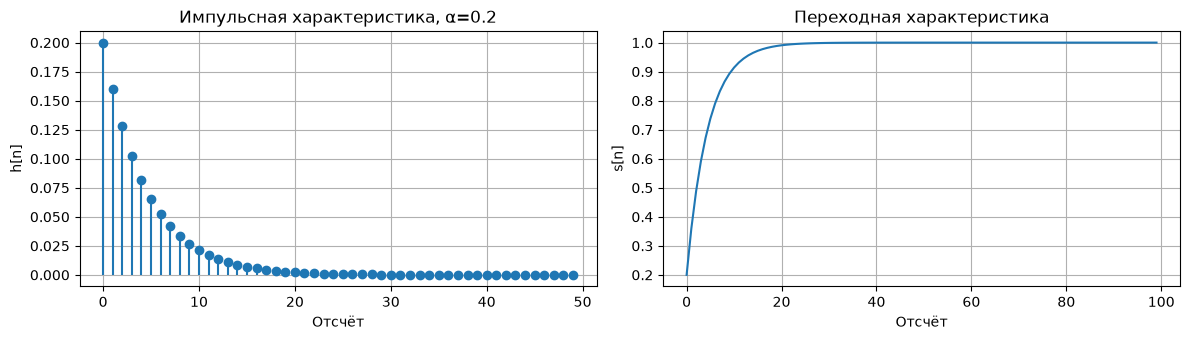

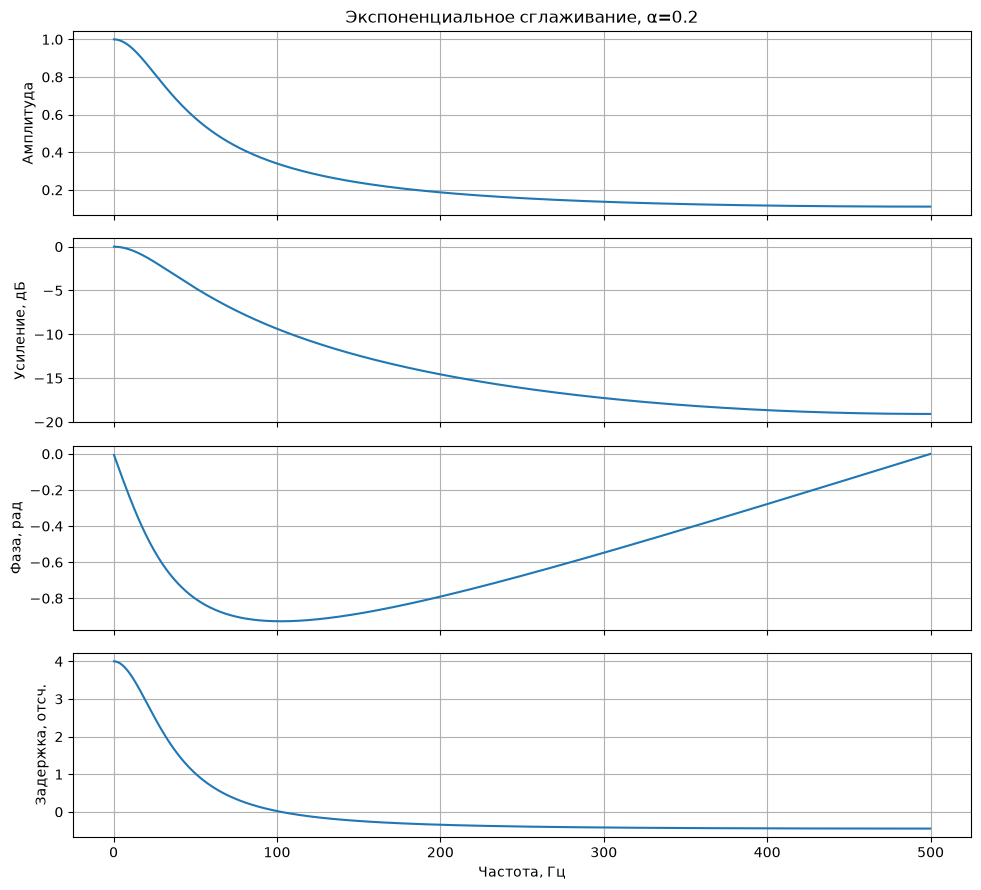

Полюс: [0.8]


In [5]:
alpha = 0.2
b, a = [alpha], [1, -(1-alpha)]
impulse = np.zeros(50)
impulse[0] = 1
h = signal.lfilter(b, a, impulse)
s = signal.lfilter(b, a, np.ones(100))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].stem(h, basefmt=' ')
axes[0].set(title='Импульсная характеристика, α=0.2', xlabel='Отсчёт', ylabel='h[n]')
axes[1].plot(s)
axes[1].set(title='Переходная характеристика', xlabel='Отсчёт', ylabel='s[n]')
plt.tight_layout()
plt.show()
plot_filter_response(b, a, fs=1000, title='Экспоненциальное сглаживание, α=0.2')
z, p, k = signal.tf2zpk(b, a)
print('Полюс:', p)

**Вопрос:** Где расположен полюс передаточной функции при `α = 0.2`? Как расстояние от полюса до единичной окружности связано со скоростью затухания импульсной характеристики?

полюс 0,8 и $H(z)=0.2/(1-0.8z^{-1})$. Полюс внутри единичной окружности, поэтому хвост затухает как $0.2\cdot0.8^n$. Чем ближе полюс к единице, тем дольше фильтр помнит старые значения.

### Задание 2.2. Влияние параметра α

Исследуйте фильтр при `α = 0.05, 0.2, 0.8`. Постройте на одном графике АЧХ (в дБ) и на другом – групповую задержку. Сделайте выводы.


α=0.05: низкочастотная групповая задержка 19.00 отсч.
α=0.2: низкочастотная групповая задержка 4.00 отсч.
α=0.8: низкочастотная групповая задержка 0.25 отсч.


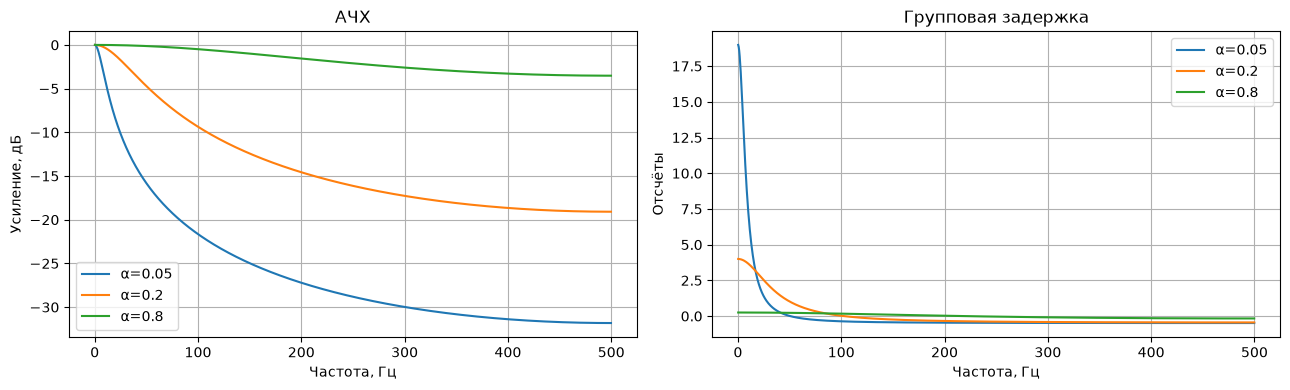

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for alpha in [0.05, 0.2, 0.8]:
    f, H, gd = response([alpha], [1, -(1-alpha)], 1000)
    axes[0].plot(f, 20*np.log10(np.abs(H)), label=f'α={alpha}')
    axes[1].plot(f, gd, label=f'α={alpha}')
    print(f'α={alpha}: низкочастотная групповая задержка {(1-alpha)/alpha:.2f} отсч.')
axes[0].set(title='АЧХ', xlabel='Частота, Гц', ylabel='Усиление, дБ')
axes[1].set(title='Групповая задержка', xlabel='Частота, Гц', ylabel='Отсчёты')
for ax in axes: ax.legend()
plt.tight_layout()
plt.show()

**Вопрос:** Как α влияет на скорость реакции фильтра на изменение сигнала и на крутизну спада АЧХ?


Маленькое α даёт более гладкий результат, но фильтр медленнее реагирует. При α=0,8 он повторяет вход. уменьшая α, мы сильнее сглаживаем высокие частоты, но получаем больше задержки.

### Задание 2.3. Фильтрация зашумлённого сигнала

Сгенерируйте сигнал: синусоида 20 Гц + белый шум (SNR ≈ 5 дБ), fs=500 Гц. Примените экспоненциальный фильтр с α = 0.1 и α = 0.5. Постройте исходный и отфильтрованные сигналы (первые 0.2 с). Сравните степень сглаживания и задержку.


Входной SNR: 5.00 дБ
α=0.1: усиление на 20 Гц 0.388, фазовая задержка 8.36 мс
α=0.5: усиление на 20 Гц 0.943, фазовая задержка 1.88 мс


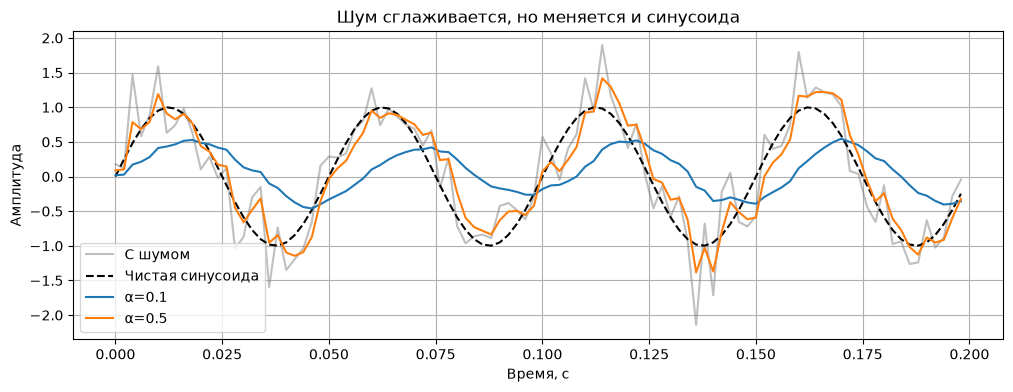

In [7]:
fs = 500
t = np.arange(fs)/fs
x_clean = np.sin(2*np.pi*20*t)
noise = np.random.randn(len(t))
noise *= np.sqrt(np.mean(x_clean**2)/10**(5/10))/np.std(noise)
x_noisy = x_clean + noise
print(f'Входной SNR: {10*np.log10(np.mean(x_clean**2)/np.mean(noise**2)):.2f} дБ')
plt.plot(t[:100], x_noisy[:100], color='gray', alpha=.5, label='С шумом')
plt.plot(t[:100], x_clean[:100], 'k--', label='Чистая синусоида')
for alpha in [0.1, 0.5]:
    y = signal.lfilter([alpha], [1, -(1-alpha)], x_noisy)
    plt.plot(t[:100], y[:100], label=f'α={alpha}')
    _, H = signal.freqz([alpha], [1, -(1-alpha)], worN=[20], fs=fs)
    print(f'α={alpha}: усиление на 20 Гц {abs(H[0]):.3f}, фазовая задержка {-np.angle(H[0])/(2*np.pi*20)*1000:.2f} мс')
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.title('Шум сглаживается, но меняется и синусоида')
plt.legend()
plt.show()

**Вопрос:** Как на временных графиках проявляется групповая задержка, вносимая БИХ-фильтром?


Вершины сместились вправо, особенно при α=0,1. Заодно уменьшилась амплитуда самой синусоиды. У БИХ задержка зависит от частоты, поэтому сложный сигнал может ещё и поменять форму.

## Часть 3. Фильтр Савицкого – Голея (Savitzky–Golay)

Этот КИХ-фильтр основан на локальной полиномиальной регрессии. Он сохраняет форму сигнала (пики, перегибы) лучше, чем скользящее среднее.

### Задание 3.1. Базовое применение и влияние параметров

Сгенерируйте синусоиду 5 Гц (fs=100 Гц, длительность 2 с) и добавьте белый шум (дисперсия 0.2). Примените `savgol_filter` с параметрами:
- (window=11, polyorder=2)
- (window=21, polyorder=2)
- (window=11, polyorder=5)

Постройте исходный чистый сигнал, зашумлённый и три сглаженные версии. Объясните влияние параметров.


Окно 11, степень 2: RMSE=0.2037
Окно 21, степень 2: RMSE=0.2784
Окно 11, степень 5: RMSE=0.2620


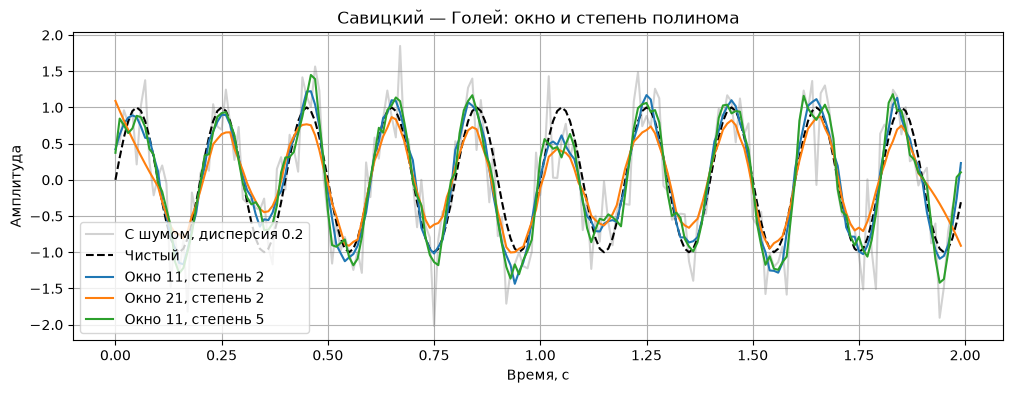

In [8]:
fs = 100
t = np.arange(2*fs)/fs
x_clean = np.sin(2*np.pi*5*t)
x_noisy = x_clean + np.sqrt(0.2)*np.random.randn(len(t))
plt.plot(t, x_noisy, color='gray', alpha=.35, label='С шумом, дисперсия 0.2')
plt.plot(t, x_clean, 'k--', label='Чистый')
for win, degree in [(11, 2), (21, 2), (11, 5)]:
    y = savgol_filter(x_noisy, win, degree)
    plt.plot(t, y, label=f'Окно {win}, степень {degree}')
    print(f'Окно {win}, степень {degree}: RMSE={np.sqrt(np.mean((y-x_clean)**2)):.4f}')
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.title('Савицкий — Голей: окно и степень полинома')
plt.legend()
plt.show()

**Вопрос:** Как увеличение `window_length` и увеличение `polyorder` влияют на степень сглаживания и сохранение формы сигнала?


Большое окно лучше прибирает шум, но начинает сглаживать и нашу синусоиду. Высокая степень полинома лучше повторяет форму, зато может повторить и шум. Для этого примера я бы выбрал 11/2: у него получилась наименьшая ошибка среди трёх вариантов.

### Задание 3.2. Сравнение со скользящим средним

Создайте сигнал с острым пиком (гауссов импульс с σ=3) на фоне шума. Примените скользящее среднее (window=11) и Savitzky–Golay (window=11, polyorder=2). Сравните, какой фильтр лучше сохраняет форму пика.


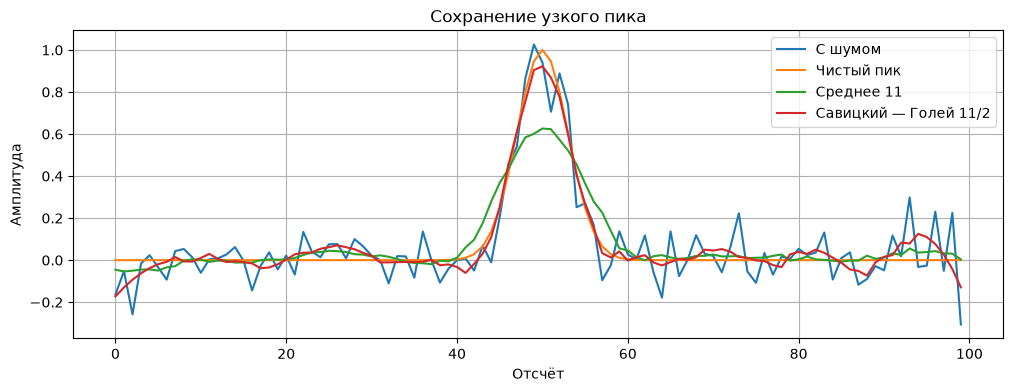

Высота в центре: исходная 1.000, среднее 0.626, Савицкий — Голей 0.923


In [9]:
N = 100
n = np.arange(N)
x_clean_pulse = np.exp(-(n-N//2)**2/(2*3**2))
x_noisy_pulse = x_clean_pulse + 0.1*np.random.randn(N)
pulse_ma = np.convolve(x_noisy_pulse, np.ones(11)/11, mode='same')
pulse_sg = savgol_filter(x_noisy_pulse, 11, 2)
for label, y in [('С шумом', x_noisy_pulse), ('Чистый пик', x_clean_pulse), ('Среднее 11', pulse_ma), ('Савицкий — Голей 11/2', pulse_sg)]:
    plt.plot(n, y, label=label)
plt.xlabel('Отсчёт')
plt.ylabel('Амплитуда')
plt.title('Сохранение узкого пика')
plt.legend()
plt.show()
print(f'Высота в центре: исходная {x_clean_pulse[50]:.3f}, среднее {pulse_ma[50]:.3f}, Савицкий — Голей {pulse_sg[50]:.3f}')

**Вопрос:** Какой из фильтров лучше сохраняет пик?


У меня SG лучше сохранил узкий пик: высота около 0,92, а у среднего только около 0,63. Среднее ещё и расширило пик. Ну, идеального восстановления тут всё равно нет: шум остаётся.

### Задание 3.3. Частотные характеристики

Получите коэффициенты Savitzky–Golay для `window_length=11, polyorder=2` с помощью `savgol_coeffs`. Нормируйте их так, чтобы сумма была равна 1. Постройте АЧХ этого фильтра и сравните с АЧХ скользящего среднего той же длины.


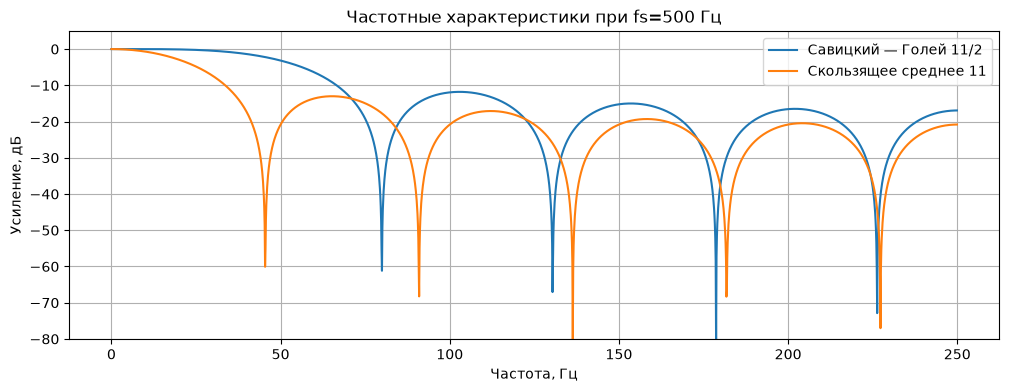

Сумма коэффициентов SG: 1.0


In [10]:
coeffs = savgol_coeffs(11, 2)
coeffs /= coeffs.sum()
for label, b in [('Савицкий — Голей 11/2', coeffs), ('Скользящее среднее 11', np.ones(11)/11)]:
    f, H = signal.freqz(b, [1], worN=2048, fs=500)
    plt.plot(f, 20*np.log10(abs(H) + 1e-12), label=label)
plt.xlabel('Частота, Гц')
plt.ylabel('Усиление, дБ')
plt.ylim(-80, 5)
plt.title('Частотные характеристики при fs=500 Гц')
plt.legend()
plt.show()
print('Сумма коэффициентов SG:', coeffs.sum())

**Вопрос:** Чем отличается АЧХ Savitzky–Golay от АЧХ скользящего среднего? Как это объясняет сохранение формы сигнала?


У SG АЧХ на низких частотах дольше остаётся около единицы. Поэтому он меньше уменьшает полезные детали. Среднее начинает подавлять их раньше. За сохранение формы у SG мы платим более слабым подавлением части высоких частот.

### Задание 3.4. Фильтрация меандра

Сгенерируйте меандр частотой 2 Гц (fs=500 Гц) и добавьте синусоидальную помеху 50 Гц амплитудой 0.5. Примените Savitzky–Golay (window=15, polyorder=3) и скользящее среднее (window=15). Сравните, как подавляется помеха и сохраняются фронты.


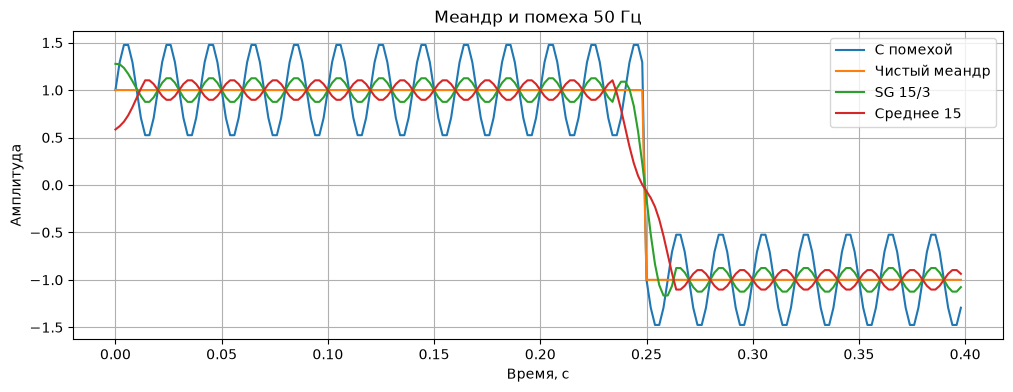

SG: остаточная амплитуда помехи 0.1308
Среднее: остаточная амплитуда помехи 0.1079


In [11]:
fs = 500
t = np.arange(fs)/fs
meander = signal.square(2*np.pi*2*t)
x_meander = meander + 0.5*np.sin(2*np.pi*50*t)
y_sg = savgol_filter(x_meander, 15, 3)
y_ma = np.convolve(x_meander, np.ones(15)/15, mode='same')
for label, y in [('С помехой', x_meander), ('Чистый меандр', meander), ('SG 15/3', y_sg), ('Среднее 15', y_ma)]:
    plt.plot(t[:200], y[:200], label=label)
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.title('Меандр и помеха 50 Гц')
plt.legend()
plt.show()
for label, b in [('SG', savgol_coeffs(15, 3)), ('Среднее', np.ones(15)/15)]:
    _, H = signal.freqz(b, [1], worN=[50], fs=fs)
    print(f'{label}: остаточная амплитуда помехи {0.5*abs(H[0]):.4f}')

**Вопрос:** Какой фильтр лучше подходит для обработки сигналов с резкими фронтами? Почему?


Я бы выбрал SG, если важнее сохранить узкий переход, но у него возле скачка есть выбросы. Среднее сильнее размывает фронт. Для резких фронтов с одиночными помехами дальше стоит посмотреть медианный фильтр.

## Часть 4. Сравнение КИХ и БИХ фильтров

### Задание 4.1. Сравнение скользящего среднего, экспоненциального фильтра и фильтра Савицкого – Голея

Для скользящего среднего (`M=10`), экспоненциального фильтра (`α=0.2`) и Savitzky–Golay (`win=11, polyorder=2`):

1. Постройте на одном графике их АЧХ (в дБ) и групповую задержку.
2. Подайте на них единичный импульс и единичный скачок, постройте реакции.
3. Сгенерируйте сигнал из прямоугольных импульсов с шумом (как в примере ниже) и примените все три фильтра. Оцените качество подавления шума и сохранения фронтов.


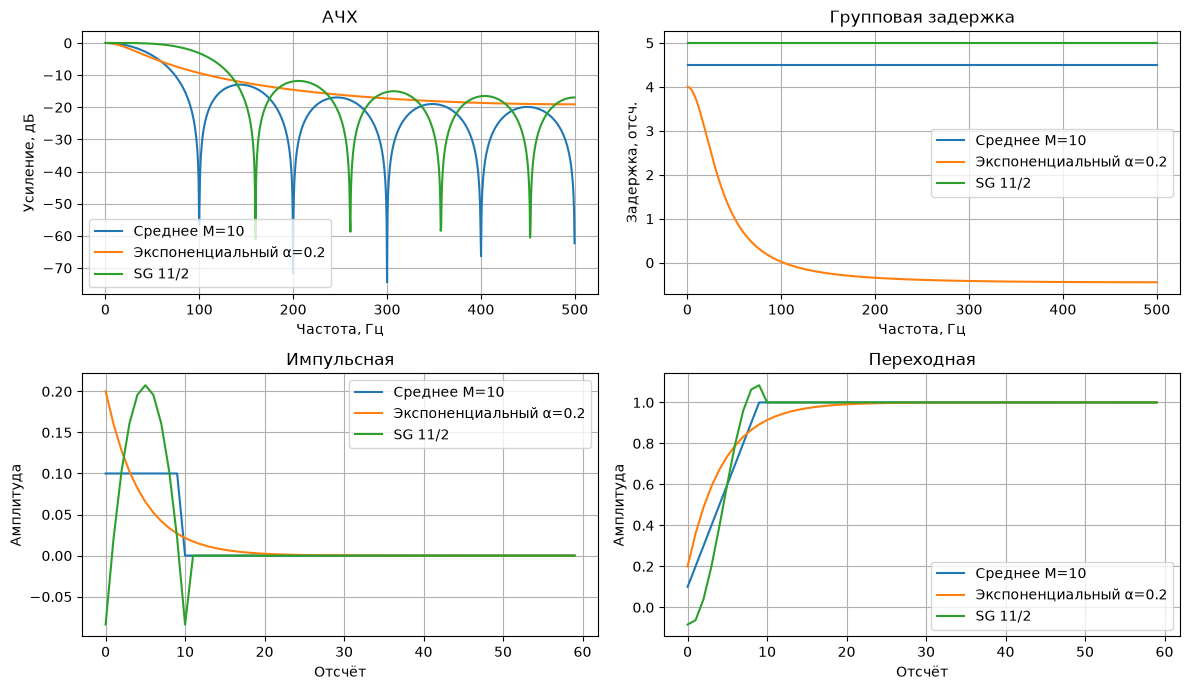

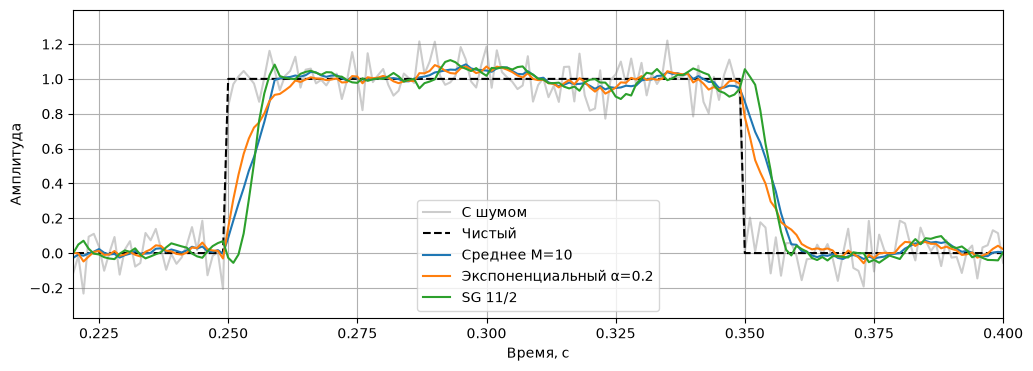

In [12]:
fs = 1000
t = np.arange(fs)/fs
pulse_train = (np.arange(fs) % 250 < 100).astype(float)
x_pulse_noisy = pulse_train + 0.1*np.random.randn(fs)
filters = {
    'Среднее M=10': (np.ones(10)/10, [1]),
    'Экспоненциальный α=0.2': ([0.2], [1, -0.8]),
    'SG 11/2': (savgol_coeffs(11, 2), [1]),
}
impulse = np.r_[1., np.zeros(59)]
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for name, (b, a) in filters.items():
    f, H, gd = response(b, a, fs)
    axes[0, 0].plot(f, 20*np.log10(abs(H)+1e-12), label=name)
    axes[0, 1].plot(f, gd, label=name)
    axes[1, 0].plot(signal.lfilter(b, a, impulse), label=name)
    axes[1, 1].plot(signal.lfilter(b, a, np.ones(60)), label=name)
for ax, title, xlabel, ylabel in zip(axes.flat,
        ['АЧХ', 'Групповая задержка', 'Импульсная', 'Переходная'],
        ['Частота, Гц', 'Частота, Гц', 'Отсчёт', 'Отсчёт'],
        ['Усиление, дБ', 'Задержка, отсч.', 'Амплитуда', 'Амплитуда']):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend()
plt.tight_layout()
plt.show()
plt.plot(t, x_pulse_noisy, color='gray', alpha=0.4, label='С шумом')
plt.plot(t, pulse_train, 'k--', label='Чистый')
for name, (b, a) in filters.items():
    plt.plot(t, signal.lfilter(b, a, x_pulse_noisy), label=name)
plt.xlim(0.22, 0.4)
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.legend()
plt.show()

**Вопрос:** Какой фильтр обеспечивает наилучшее подавление шума? Какой лучше сохраняет фронты? Какой имеет наименьшие фазовые искажения?


По ровным участкам среднее и экспоненциальный фильтр сильнее приглушают шум. SG лучше сохраняет быстрый переход, но может дать выброс. У среднего и SG задержка постоянная — 4,5 и 5 отсчётов, поэтому после учёта сдвига форма не портится из-за нелинейной фазы. У экспоненциального задержка зависит от частоты.

## Часть 5. Нелинейная фильтрация: медианный фильтр

**Медианный фильтр** заменяет каждый отсчёт медианой значений в окне нечётной длины $K$:
$$
y[n] = \operatorname{median}\{x[n-k], \dots, x[n], \dots, x[n+k]\}, \qquad K = 2k+1.
$$
В Python: `signal.medfilt(x, kernel_size=K)`. Фильтр нелинеен: для него не выполняется принцип суперпозиции, поэтому его нельзя описать импульсной характеристикой и АЧХ.

### Задание 5.1. Подавление импульсных помех

Сгенерируйте синусоиду 5 Гц (fs=500 Гц, длительность 1 с) с белым шумом (σ = 0.05). Замените 5 % случайно выбранных отсчётов значениями ±2 (импульсная помеха типа «соль и перец»). Отфильтруйте сигнал:
- медианным фильтром с `K = 5` и `K = 11`;
- скользящим средним длины 11;
- фильтром Савицкого – Голея (window=11, polyorder=2).

Постройте графики и вычислите среднеквадратичную ошибку каждого результата относительно чистой синусоиды.

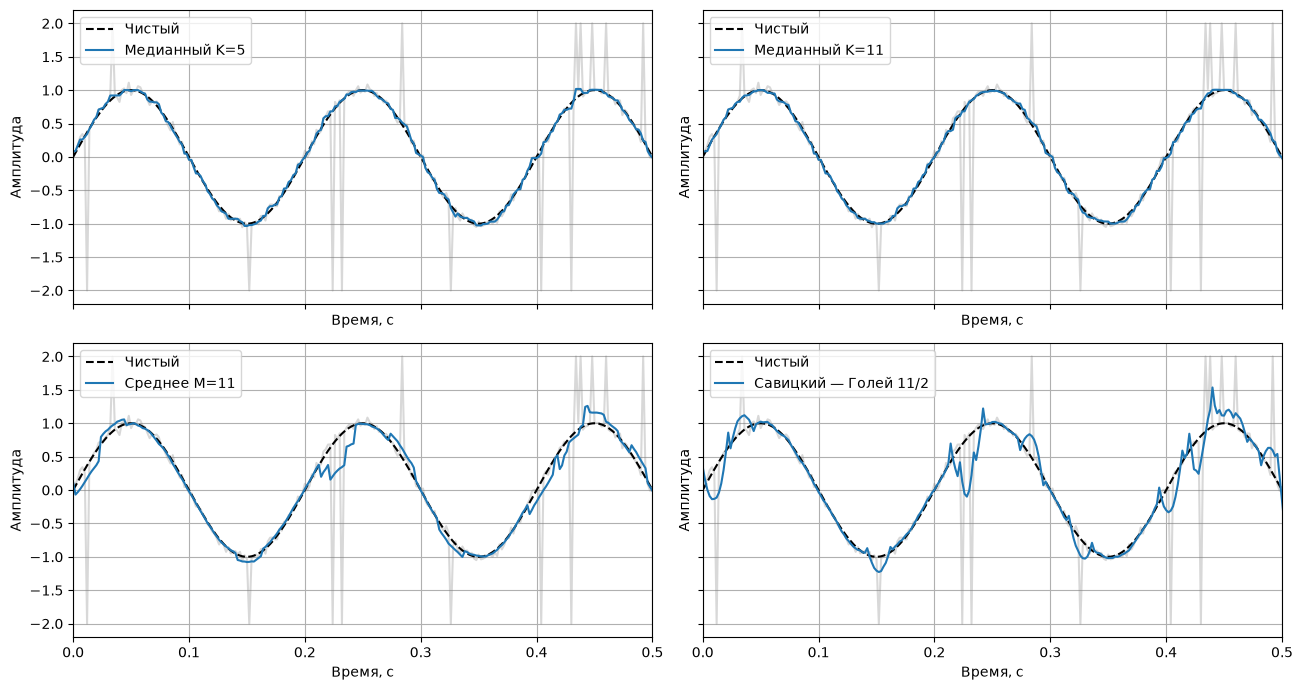

Без фильтра               RMSE = 0.44225
Медианный K=5             RMSE = 0.03738
Медианный K=11            RMSE = 0.03657
Среднее M=11              RMSE = 0.14245
Савицкий — Голей 11/2     RMSE = 0.20267


In [13]:
np.random.seed(0)
fs = 500
t = np.arange(fs)/fs
x_clean = np.sin(2*np.pi*5*t)
x_noisy = x_clean + 0.05*np.random.randn(fs)
idx = np.random.choice(fs, int(.05*fs), replace=False)
x_noisy[idx] = np.random.choice([-2, 2], size=len(idx))
results = {
    'Без фильтра': x_noisy,
    'Медианный K=5': signal.medfilt(x_noisy, 5),
    'Медианный K=11': signal.medfilt(x_noisy, 11),
    'Среднее M=11': np.convolve(x_noisy, np.ones(11)/11, mode='same'),
    'Савицкий — Голей 11/2': savgol_filter(x_noisy, 11, 2),
}
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)
for ax, (label, y) in zip(axes.flat, list(results.items())[1:]):
    ax.plot(t, x_noisy, color='gray', alpha=.3)
    ax.plot(t, x_clean, 'k--', label='Чистый')
    ax.plot(t, y, label=label)
    ax.set(xlabel='Время, с', ylabel='Амплитуда', xlim=(0, .5))
    ax.legend()
plt.tight_layout()
plt.show()
for label, y in results.items():
    print(f'{label:25s} RMSE = {np.sqrt(np.mean((y-x_clean)**2)):.5f}')

**Вопрос:** Какой фильтр лучше справляется с импульсной помехой? Почему линейные фильтры здесь проигрывают, даже фильтр Савицкого – Голея?

На выбросах лучше всего сработала медиана. Одна большая точка не меняет медиану, пока нормальных соседей больше. А среднее и SG размазывают выброс по нескольким точкам, поэтому их ошибка тут больше.

### Задание 5.2. Сохранение фронтов

Возьмите последовательность прямоугольных импульсов из задания 4.1 и добавьте к ней импульсную помеху: замените 2 % отсчётов значениями ±1. Сравните медианный фильтр (`K = 11`) и скользящее среднее (`M = 11`):
1. Постройте фрагмент сигнала вокруг одного из фронтов до и после фильтрации.
2. Оцените длительность фронта после фильтрации – число отсчётов, за которое сигнал растёт от уровня 0.1 до уровня 0.9.

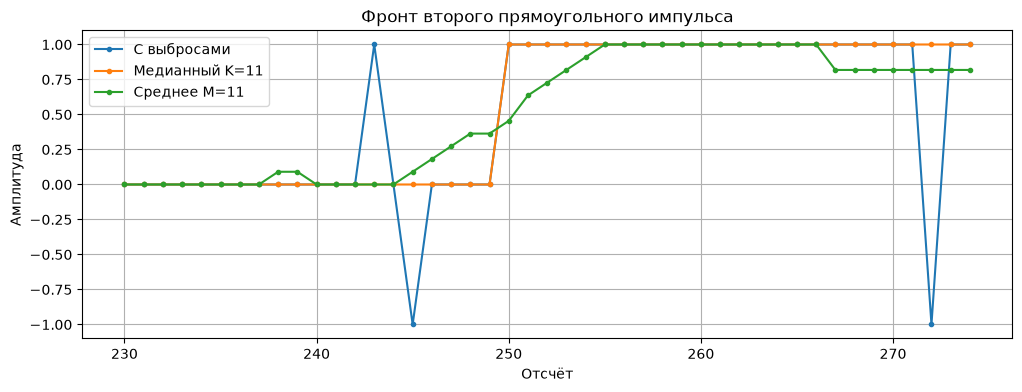

In [14]:
# Здесь оставляем только импульсную помеху: так виднее, что происходит с фронтом.
rng = np.random.default_rng(52)
x_edges = pulse_train.copy()
idx = rng.choice(len(x_edges), int(.02*len(x_edges)), replace=False)
x_edges[idx] = rng.choice([-1, 1], len(idx))
edge_med = signal.medfilt(x_edges, 11)
edge_ma = np.convolve(x_edges, np.ones(11)/11, mode='same')
for label, y in [('С выбросами', x_edges), ('Медианный K=11', edge_med), ('Среднее M=11', edge_ma)]:
    plt.plot(np.arange(230, 275), y[230:275], 'o-', ms=3, label=label)
plt.xlabel('Отсчёт')
plt.ylabel('Амплитуда')
plt.title('Фронт второго прямоугольного импульса')
plt.legend()
plt.show()

**Вопрос:** Почему медианный фильтр не размывает фронт, а скользящее среднее размывает?

Медиана выбирает один из уровней около фронта: какой чаще попался в окно, тот и остаётся. Среднее смешивает два уровня и рисует промежуточные значения. Поэтому на моём графике медиана оставила резкий скачок, а среднее его растянуло.

### Задание 5.3. Нелинейность медианного фильтра

1. Подайте на медианный фильтр (`K = 5`) единичный импульс. Чему равна его «импульсная характеристика»?
2. Возьмите $x_1$ – единичный скачок (длина 50, скачок в отсчёте 25) и $x_2$ – одиночный выброс амплитуды 3 в отсчёте 10. Сравните `medfilt(x1 + x2)` и `medfilt(x1) + medfilt(x2)`.
3. Подайте на фильтр с `K = 5` прямоугольные импульсы шириной 1, 2, 3 и 4 отсчёта. Какие из них сохранятся после фильтрации?

Выход на единичный импульс: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Пример из задания, максимальное расхождение: 0.0
Контрпример, максимальное расхождение: 1.0


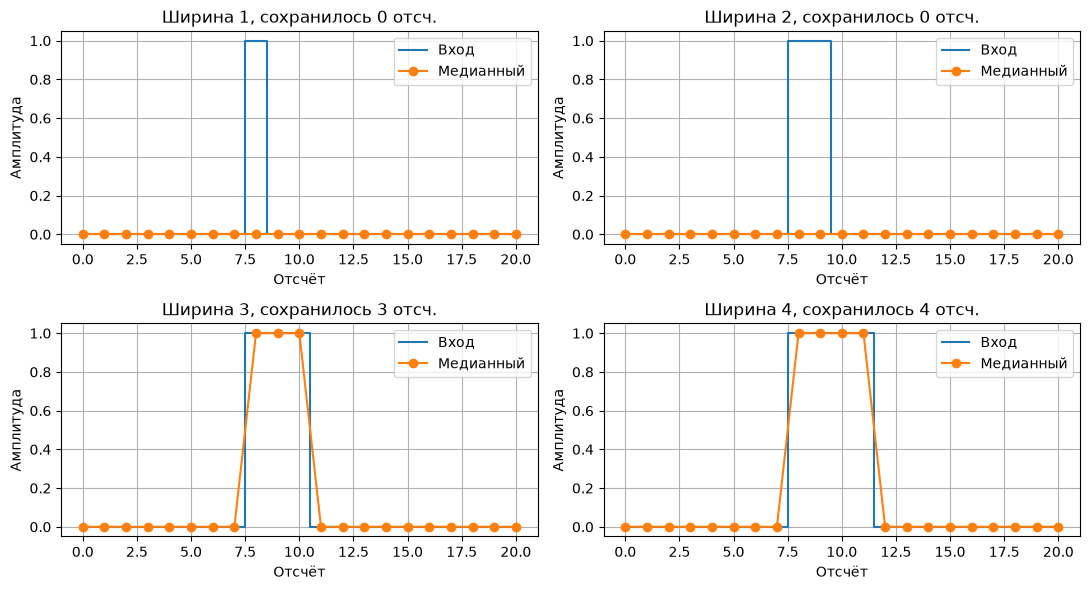

In [15]:
K = 5
impulse = np.zeros(21)
impulse[10] = 1
print('Выход на единичный импульс:', signal.medfilt(impulse, K))
x1 = np.zeros(50)
x1[25:] = 1
x2 = np.zeros(50)
x2[10] = 3
lhs = signal.medfilt(x1+x2, K)
rhs = signal.medfilt(x1, K) + signal.medfilt(x2, K)
print('Пример из задания, максимальное расхождение:', np.max(abs(lhs-rhs)))

# У далёких импульсов разницы нет. Проверяю ещё соседние импульсы.
a = np.zeros(21)
b = np.zeros(21)
a[8:10] = 1
b[10] = 1
lhs2 = signal.medfilt(a+b, K)
rhs2 = signal.medfilt(a, K) + signal.medfilt(b, K)
print('Контрпример, максимальное расхождение:', np.max(abs(lhs2-rhs2)))
fig, axes = plt.subplots(2, 2, figsize=(11, 6))
for ax, width in zip(axes.flat, [1, 2, 3, 4]):
    p = np.zeros(21)
    p[8:8+width] = 1
    y = signal.medfilt(p, K)
    ax.step(np.arange(21), p, where='mid', label='Вход')
    ax.plot(y, 'o-', label='Медианный')
    ax.set(title=f'Ширина {width}, сохранилось {np.count_nonzero(y)} отсч.', xlabel='Отсчёт', ylabel='Амплитуда')
    ax.legend()
plt.tight_layout()
plt.show()

**Вопрос:** Можно ли описать медианный фильтр импульсной характеристикой и АЧХ? Какие детали сигнала он удаляет, а какие сохраняет? Как минимальная ширина сохраняющегося импульса связана с длиной окна $K$?

Одиночный импульс медиана убрала, но это не значит, что её выход всегда нулевой. Она нелинейна, так что обычной импульсной характеристикой и АЧХ мы её не опишем. Пример с далёким выбросом случайно дал равенство, а на соседних импульсах оно уже нарушилось. При K=5 у меня сохранились импульсы от трёх отсчётов: нужно хотя бы (K+1)/2 одинаковых точек в окне.

## Общий вывод

После этих опытов стало понятнее, что самый гладкий график не всегда самый правильный. Большое окно хорошо убирает шум, но заодно съедает пики и быстрые изменения. Для обычного шума можно начать со среднего или SG, для одиночных выбросов медианный фильтр оказался заметно удачнее. И ещё стоит смотреть на задержку: красивый выходной сигнал может просто запаздывать относительно входа.